# P6 — Wi-Fi Indoor Localisation
**Group G6 · Paracetamol** — Applied Machine Learning Lab

| Member | Roll no. | Owns (model) | Owns (notebook / report section) |
|---|---|---|---|
| Philem Arjun | 2481034 | K-Means | §0 Setup & split, §1 EDA, §2 Unsupervised clustering |
| Dhruv Rangan | 2481048 | KNN, SVM | §4 Supervised methodology (pipeline, metric, tuning) |
| Yashveer Singh | 2481242 | Random Forest | §5 Robustness (AP failure, noise), §6 Final test |
| Harsh Kumar | 2481121 | Logistic Regression (+ Dummy baseline), Decision Tree | §3 PCA, §7 Interpretation & limitations |

**Problem.** Predict which of 4 rooms a smartphone is in from the received signal strength (RSSI, in dBm) of 7 Wi-Fi access points (APs) — first without labels (clustering), then with labels (classification).

**Dataset.** UCI *Wireless Indoor Localization* (Rohra et al., 2017; CC BY 4.0): 2,000 readings × 7 APs, label = room 1–4.

**How to run.** `Kernel → Restart & Run All`. Every random step uses `RANDOM_STATE = 42`, so the outputs are identical on every run.

**Notebook map:** 0 Setup → split → 1 EDA → 2 K-Means → 3 PCA → 4 Supervised models → 5 Robustness (CV) → 6 Final test-set evaluation (test set used **once**) → 7 Interpretation → 8 Limitations

## 0. Setup and reproducibility

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.optimize import linear_sum_assignment

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.feature_selection import f_classif
from sklearn.metrics import (f1_score, accuracy_score, adjusted_rand_score, silhouette_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# ---- one seed for everything -------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
N_JOBS = -1          # parallelism does not change results: every estimator has a fixed random_state

DATA_URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/00422/wifi_localization.txt"
DATA_PATH = Path("data/wifi_localization.txt")
FIG_DIR   = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR   = Path("results"); RES_DIR.mkdir(exist_ok=True)

AP_COLS = [f"AP{i}" for i in range(1, 8)]
ROOMS   = [1, 2, 3, 4]
ROOM_NAMES = [f"Room {r}" for r in ROOMS]
PALETTE = dict(zip(ROOM_NAMES, sns.color_palette("tab10", 4)))

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)
warnings.filterwarnings("ignore", category=FutureWarning)

# 5-fold stratified CV, shuffled with the fixed seed. Used for tuning and for every mean ± SD claim.
CV       = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CV_OUTER = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1)  # outer loop of nested CV

def pm(scores, d=3):
    # mean ± sample standard deviation (ddof=1) across CV folds
    s = np.asarray(scores, dtype=float)
    return f"{s.mean():.{d}f} ± {s.std(ddof=1):.{d}f}"

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.13.14 | numpy 2.2.6 | pandas 2.2.3 | scikit-learn 1.6.1 | matplotlib 3.10.3 | seaborn 0.13.2


In [2]:
# Load (downloads once from UCI if the file is not in data/)
if not DATA_PATH.exists():
    import urllib.request
    DATA_PATH.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=AP_COLS + ["room"])
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Class counts:", df["room"].value_counts().sort_index().to_dict())
df.head()

Shape: (2000, 8)
Missing values: 0
Exact duplicate rows: 0
Class counts: {1: 500, 2: 500, 3: 500, 4: 500}


,AP1,AP2,AP3,AP4,AP5,AP6,AP7,room
0,-64,-56,-61,-66,-71,-82,-81,1
1,-68,-57,-61,-65,-71,-85,-85,1
2,-63,-60,-60,-67,-76,-85,-84,1
3,-61,-60,-68,-62,-77,-90,-80,1
4,-63,-65,-60,-63,-77,-81,-87,1


### Split first (leak-free protocol)
The test set (20 %, stratified by room) is separated **before** any EDA, scaling, clustering, PCA or tuning.
Everything below — including EDA — looks only at the training set. The test set is touched exactly once, in §6.

All preprocessing (`SimpleImputer` → `StandardScaler`) lives inside a scikit-learn `Pipeline`, so inside every CV fold it is fitted on that fold's training part only.
The data has no missing values, but the imputer is there on purpose: in §5/§6 a failed access point is passed as `NaN` and the pipeline fills it with the **training** median — exactly what would happen in deployment.

In [3]:
X = df[AP_COLS]
y = df["room"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, y_train.value_counts().sort_index().to_dict())
print("Test: ", X_test.shape,  y_test.value_counts().sort_index().to_dict())

Train: (1600, 7) {1: 400, 2: 400, 3: 400, 4: 400}
Test:  (400, 7) {1: 100, 2: 100, 3: 100, 4: 100}


## 1. Exploratory data analysis (Exp. 1) — *owner: Philem Arjun*
RSSI is negative dBm: **closer to 0 = stronger signal** (−40 dBm is strong, −90 dBm is barely audible).

In [4]:
eda = X_train.assign(room=y_train.map(lambda r: f"Room {r}"))
display(X_train.describe().T)
print("Mean RSSI (dBm) per room and access point:")
display(eda.groupby("room")[AP_COLS].mean().round(1))

,count,mean,std,min,25%,50%,75%,max
AP1,1600.0,-52.399,11.291,-74.0,-61.0,-55.0,-46.0,-10.0
AP2,1600.0,-55.626,3.421,-74.0,-58.0,-56.0,-53.0,-45.0
AP3,1600.0,-54.960,5.354,-73.0,-58.0,-55.0,-51.0,-40.0
AP4,1600.0,-53.654,11.387,-77.0,-63.0,-56.0,-46.0,-11.0
AP5,1600.0,-62.638,9.093,-89.0,-69.0,-64.0,-56.0,-36.0
AP6,1600.0,-81.029,6.479,-97.0,-86.0,-82.0,-77.0,-61.0
AP7,1600.0,-81.806,6.577,-98.0,-87.0,-83.0,-78.0,-63.0


Mean RSSI (dBm) per room and access point:


,AP1,AP2,AP3,AP4,AP5,AP6,AP7
room,,,,,,,
Room 1,-62.5,-56.3,-60.5,-64.2,-70.3,-82.9,-84.1
Room 2,-37.1,-56.2,-55.9,-38.2,-67.5,-72.8,-73.6
Room 3,-49.8,-54.8,-52.8,-50.8,-63.3,-81.4,-82.5
Room 4,-60.3,-55.2,-50.7,-61.4,-49.4,-87.0,-87.1


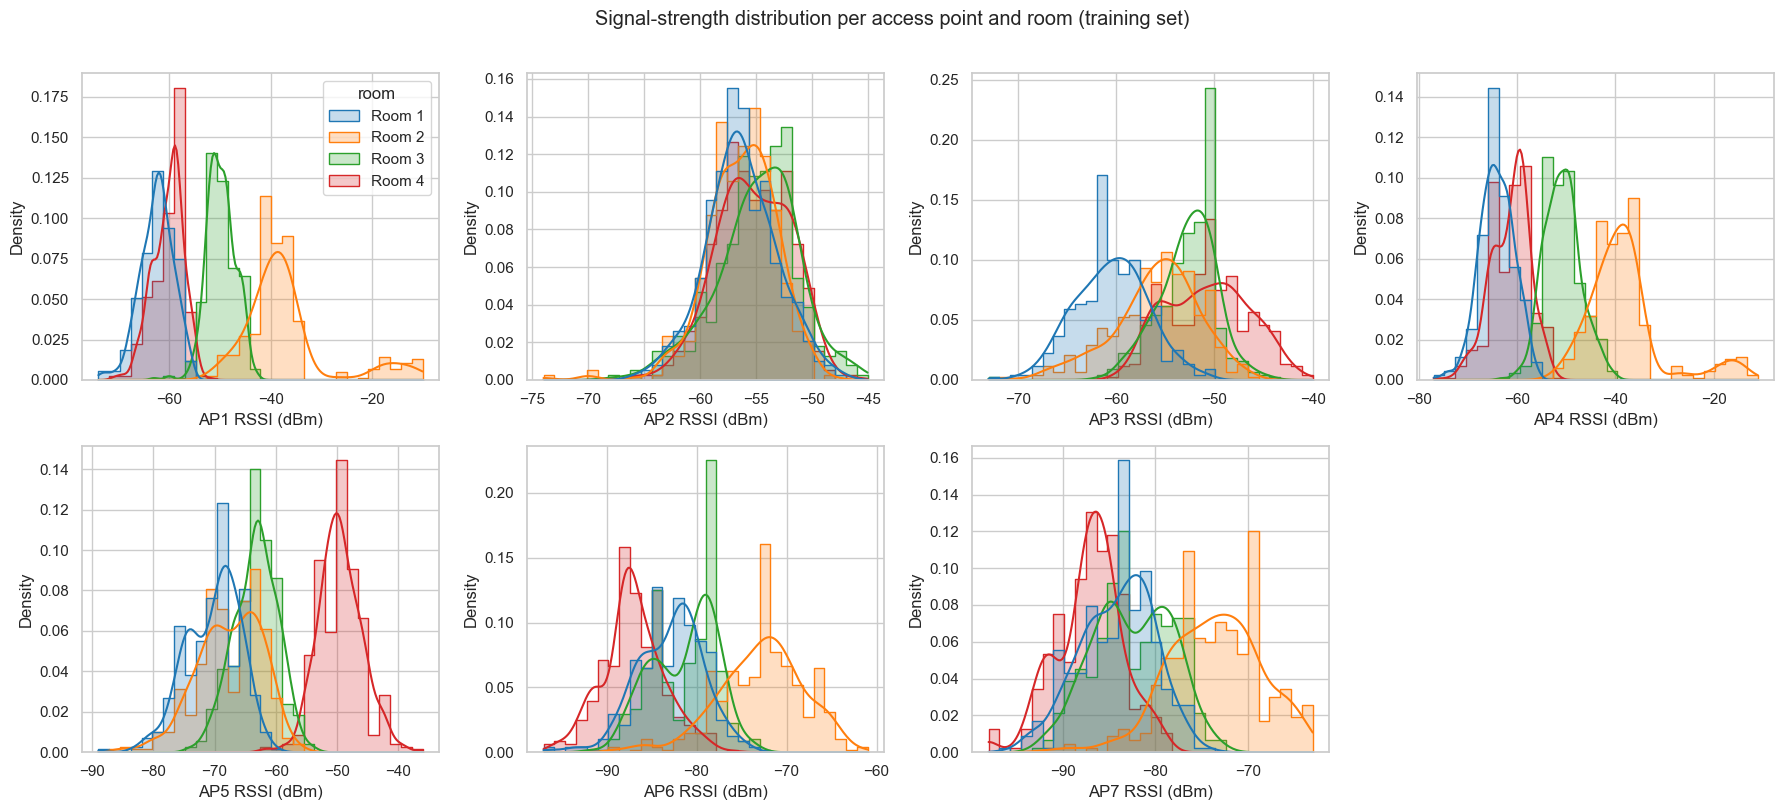

In [5]:
# Distribution of each access point, split by room
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), AP_COLS):
    sns.histplot(data=eda, x=col, hue="room", hue_order=ROOM_NAMES, palette=PALETTE,
                 kde=True, element="step", stat="density", common_norm=False, bins=30,
                 ax=ax, legend=(col == "AP1"))
    ax.set_xlabel(f"{col} RSSI (dBm)")
axes.ravel()[-1].axis("off")
fig.suptitle("Signal-strength distribution per access point and room (training set)", y=1.01)
plt.tight_layout(); savefig("eda_hist_per_ap"); plt.show()

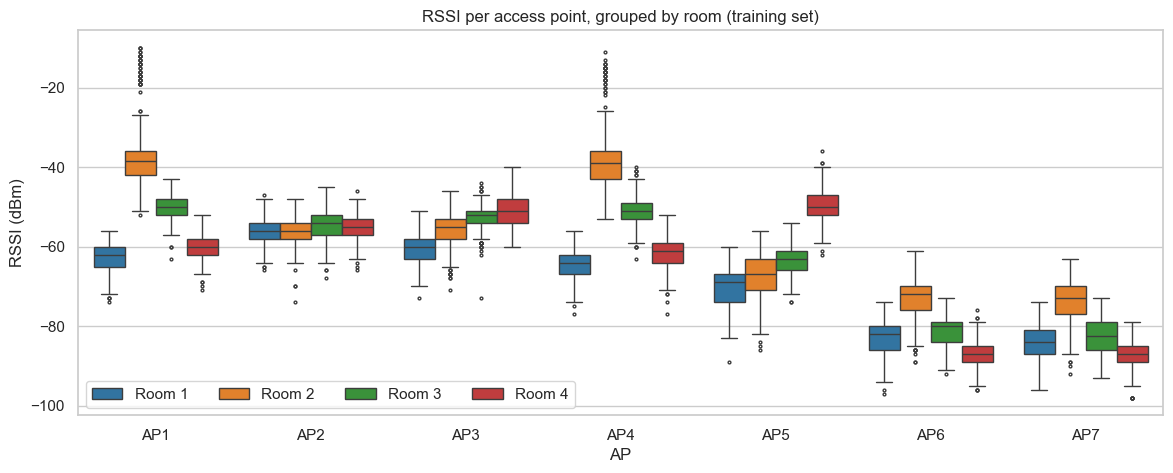

In [6]:
long = eda.melt(id_vars="room", value_vars=AP_COLS, var_name="AP", value_name="RSSI (dBm)")
plt.figure(figsize=(14, 5))
sns.boxplot(data=long, x="AP", y="RSSI (dBm)", hue="room", hue_order=ROOM_NAMES, palette=PALETTE, fliersize=2)
plt.title("RSSI per access point, grouped by room (training set)")
plt.legend(ncol=4, loc="lower left")
savefig("eda_box_per_room"); plt.show()

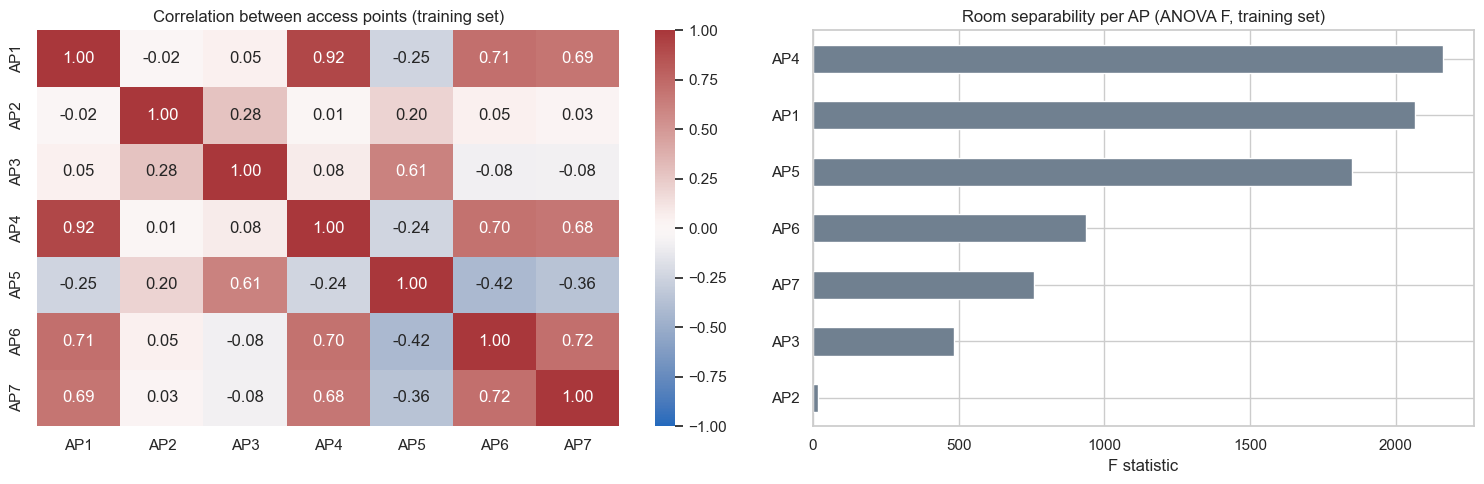

AP4    2160.0
AP1    2067.0
AP5    1850.0
AP6     936.0
AP7     757.0
AP3     485.0
AP2      19.0
dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlation between access points (training set)")

F, p = f_classif(X_train, y_train)          # one-way ANOVA: how differently does each AP behave across rooms?
anova = pd.Series(F, index=AP_COLS).sort_values()
anova.plot.barh(ax=axes[1], color="slategray")
axes[1].set_title("Room separability per AP (ANOVA F, training set)"); axes[1].set_xlabel("F statistic")
plt.tight_layout(); savefig("eda_corr_anova"); plt.show()
print(anova.sort_values(ascending=False).round(0))

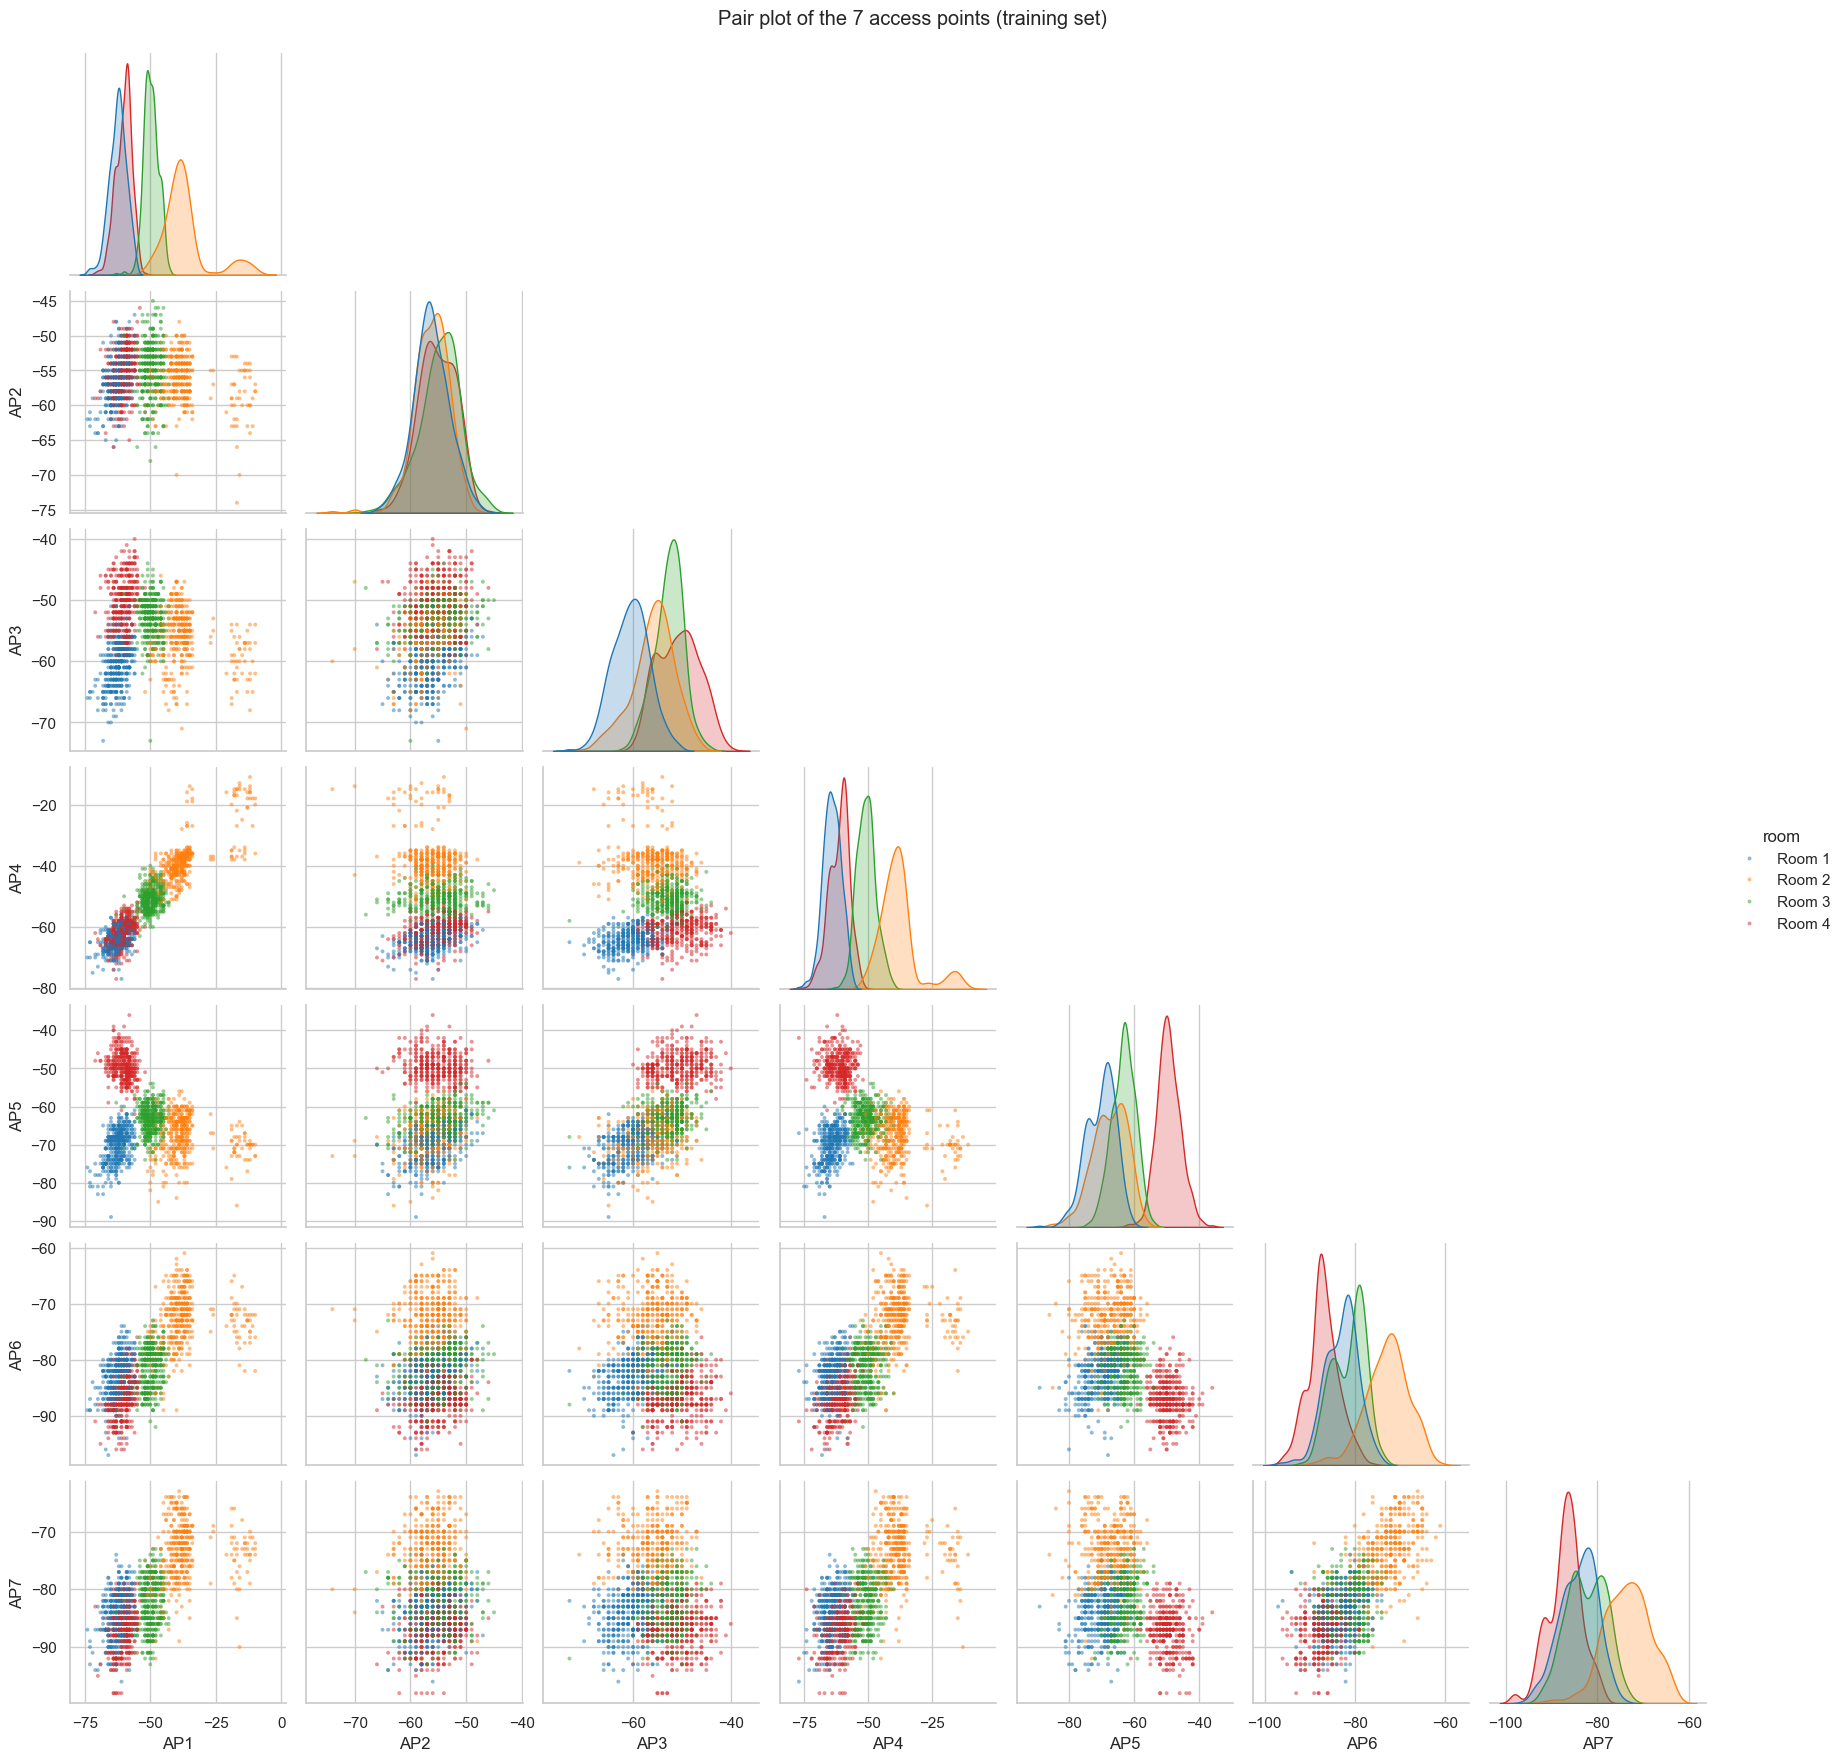

In [8]:
g = sns.pairplot(eda, hue="room", hue_order=ROOM_NAMES, palette=PALETTE, corner=True,
                 diag_kind="kde", plot_kws=dict(s=8, alpha=0.5, linewidth=0))
g.figure.suptitle("Pair plot of the 7 access points (training set)", y=1.01)
g.savefig(FIG_DIR / "eda_pairplot.png", dpi=110, bbox_inches="tight"); plt.show()

**EDA observations**
- **Clean and balanced:** 400 readings per room in training, no missing values, no duplicate rows, and all 7 features in the same unit (dBm).
- **Each room has a "signature" access point:**
  - **Room 2** hears **AP1 and AP4** far more strongly than the others (mean about −37 dBm against −50 to −64 dBm), and AP6/AP7 are also strongest there.
  - **Room 4** hears **AP5** much more strongly (about −49 dBm against −63 to −70 dBm).
  - **Room 1** is weak on almost everything.
  - **Room 3** lies *between* Room 2 and the rest on AP1/AP4, so it is the room most likely to be confused (with Room 2).
- **AP2 is almost useless:** its mean is about −55 to −56 dBm in every room (ANOVA F = 19, against roughly 2,000 for AP1/AP4/AP5).
- **Redundancy:** AP1 and AP4 are almost the same signal (r = 0.92), and both correlate about 0.7 with AP6/AP7. AP3 correlates with AP5 (0.61). So 7 APs carry only about 3 independent "directions", which PCA confirms in §3.
- Room 2 has much larger spread on AP1/AP4 (SD about 8 dBm against about 3 dBm elsewhere). Part of Room 2 is probably far from those routers, which is where it overlaps Room 3.

## 2. Unsupervised: K-Means with labels hidden (Exp. 10) — *owner: Philem Arjun*
K is chosen **only** from label-free criteria: the elbow of the inertia curve and the silhouette score.
The room labels are used afterwards, solely to *evaluate* the clusters with the Adjusted Rand Index (ARI: 1 = identical to the rooms, 0 = no better than chance).
Every number is mean ± SD over the 5 CV folds: K-Means is fitted on the fold's training part, and ARI is measured on the held-out part (`predict`).

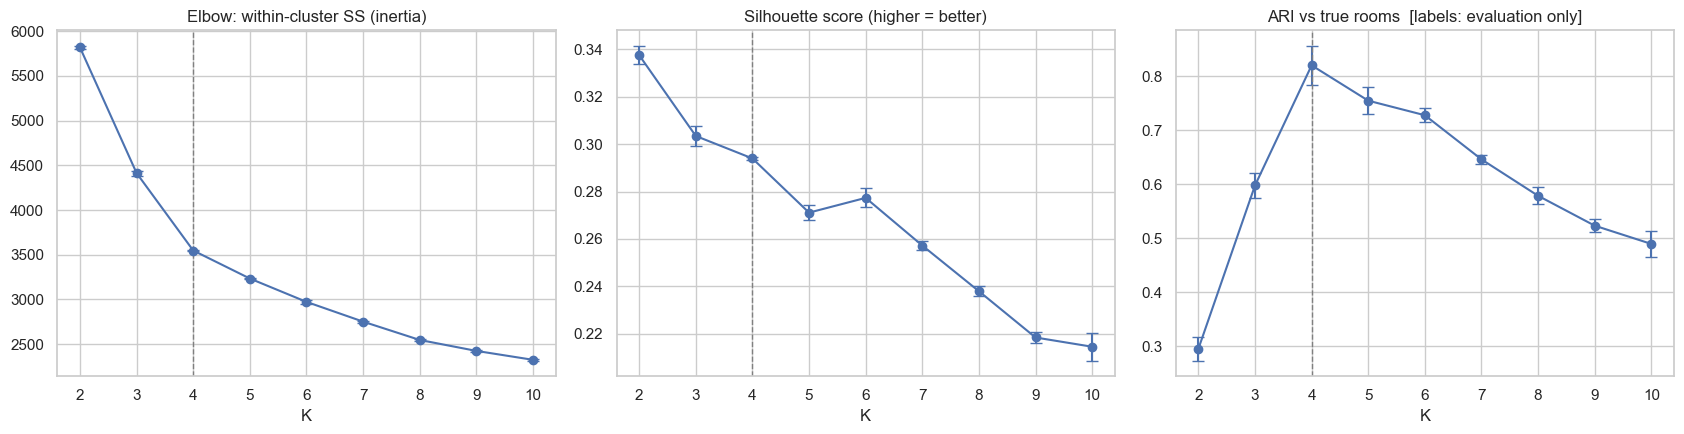

Elbow suggests K = 4;  silhouette is maximal at K = 2


,silhouette,ari
K,,
2,0.338 ± 0.004,0.295 ± 0.022
3,0.303 ± 0.004,0.598 ± 0.022
4,0.294 ± 0.001,0.820 ± 0.036
5,0.271 ± 0.003,0.755 ± 0.025
6,0.277 ± 0.004,0.728 ± 0.013
7,0.257 ± 0.002,0.646 ± 0.009
8,0.238 ± 0.002,0.579 ± 0.016
9,0.218 ± 0.002,0.523 ± 0.012
10,0.215 ± 0.006,0.490 ± 0.024


In [9]:
def kmeans_pipe(k, scale=True):
    return Pipeline([("scaler", StandardScaler() if scale else "passthrough"),
                     ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE))])

K_RANGE = range(2, 11)
rows = []
for fold, (tr, va) in enumerate(CV.split(X_train, y_train)):
    Xtr, Xva = X_train.iloc[tr], X_train.iloc[va]
    for k in K_RANGE:
        p = kmeans_pipe(k).fit(Xtr)
        Ztr = p.named_steps["scaler"].transform(Xtr)
        rows.append(dict(fold=fold, k=k,
                         inertia=p.named_steps["kmeans"].inertia_,
                         silhouette=silhouette_score(Ztr, p.named_steps["kmeans"].labels_),
                         ari=adjusted_rand_score(y_train.iloc[va], p.predict(Xva))))   # evaluation only
km_cv = pd.DataFrame(rows)
km_sum = km_cv.groupby("k")[["inertia", "silhouette", "ari"]].agg(["mean", "std"])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (m, title) in zip(axes, [("inertia", "Elbow: within-cluster SS (inertia)"),
                                 ("silhouette", "Silhouette score (higher = better)"),
                                 ("ari", "ARI vs true rooms  [labels: evaluation only]")]):
    ax.errorbar(km_sum.index, km_sum[(m, "mean")], yerr=km_sum[(m, "std")], marker="o", capsize=4)
    ax.axvline(4, ls="--", c="grey", lw=1); ax.set_xlabel("K"); ax.set_title(title)
plt.tight_layout(); savefig("kmeans_elbow_silhouette_ari"); plt.show()

# elbow = largest second difference of the mean inertia curve
inert = km_sum[("inertia", "mean")]
K_ELBOW = int(inert.diff().diff().idxmax() - 1)
K_SIL   = int(km_sum[("silhouette", "mean")].idxmax())
print(f"Elbow suggests K = {K_ELBOW};  silhouette is maximal at K = {K_SIL}")
display(pd.DataFrame({m: [pm(km_cv.loc[km_cv.k == k, m]) for k in K_RANGE]
                      for m in ["silhouette", "ari"]}, index=pd.Index(list(K_RANGE), name="K")))

In [10]:
# Decision rule (label-free): take the elbow K, provided its silhouette is clearly positive (> 0.25),
# i.e. the clusters are real structure rather than an arbitrary partition. The silhouette-optimal K_SIL is
# kept for comparison - it is evaluated below so the trade-off is visible.
K_CHOSEN = K_ELBOW if km_sum.loc[K_ELBOW, ("silhouette", "mean")] > 0.25 else K_SIL
print(f"Chosen K = {K_CHOSEN}")

def ari_cv(k, scale=True):
    return [adjusted_rand_score(y_train.iloc[va], kmeans_pipe(k, scale).fit(X_train.iloc[tr]).predict(X_train.iloc[va]))
            for tr, va in CV.split(X_train, y_train)]

ari_tab = pd.DataFrame({
    "setting": [f"K = {K_CHOSEN} (chosen: elbow), standardised", f"K = {K_SIL} (silhouette optimum), standardised",
                f"K = {K_CHOSEN}, raw dBm (no scaling)"],
    "ARI (CV mean ± SD)": [pm(ari_cv(K_CHOSEN)), pm(ari_cv(K_SIL)), pm(ari_cv(K_CHOSEN, scale=False))]})
display(ari_tab)

# Contingency table: which clusters capture which rooms (fit on the whole training set)
km_final = kmeans_pipe(K_CHOSEN).fit(X_train)
km_sil   = kmeans_pipe(K_SIL).fit(X_train)
clusters_chosen = km_final.predict(X_train)
clusters_sil    = km_sil.predict(X_train)
ct = pd.crosstab(y_train.map(lambda r: f"Room {r}"), clusters_chosen, rownames=["true room"],
                 colnames=[f"K-Means cluster (K={K_CHOSEN})"])
display(ct)

# Best one-to-one cluster→room mapping (Hungarian algorithm) → "accuracy" of clustering
r_idx, c_idx = linear_sum_assignment(-ct.values)
print(f"With the best one-to-one cluster→room mapping, K={K_CHOSEN} clustering agrees with the room on "
      f"{ct.values[r_idx, c_idx].sum() / ct.values.sum():.1%} of training readings.")

Chosen K = 4


,setting,ARI (CV mean ± SD)
0,"K = 4 (chosen: elbow), standardised",0.820 ± 0.036
1,"K = 2 (silhouette optimum), standardised",0.295 ± 0.022
2,"K = 4, raw dBm (no scaling)",0.881 ± 0.026


K-Means cluster (K=4),0,1,2,3
true room,,,,
Room 1,1,0,362,37
Room 2,0,358,6,36
Room 3,7,1,22,370
Room 4,395,0,0,5


With the best one-to-one cluster→room mapping, K=4 clustering agrees with the room on 92.8% of training readings.


**Clustering findings**
- **Choosing K.** The two label-free criteria disagree. Silhouette peaks at **K = 2** (0.338 ± 0.004), but the inertia curve has a clear elbow at **K = 4**, where silhouette is still clearly positive (0.294 ± 0.001). K = 2 is a coarse split: Room 2 against the rest, since Room 2 is the only room close to AP1/AP4/AP6/AP7. It scores ARI 0.295 ± 0.022. We take the elbow, **K = 4**.
- **The clusters recover the rooms well without any labels:** ARI = 0.820 ± 0.036 on held-out folds. With the best cluster→room mapping, about 93 % of training readings fall in "their" room's cluster. The main leakage is Room 1/Room 2 readings landing in Room 3's cluster, consistent with the EDA.
- **Scaling matters, and here standardisation *hurts*.** Raw dBm gives ARI 0.881 ± 0.026. Standardising stretches the near-useless AP2 (SD about 3 dBm) to the same weight as the informative AP1/AP4 (SD about 11 dBm), so K-Means spends effort separating noise. When all features share a physical unit, scaling is a modelling choice, not a default.

## 3. PCA: 2-D projection (Exp. 9) — *owner: Harsh Kumar*
PCA runs inside a `StandardScaler → PCA` pipeline fitted on the training set. Explained variance is reported as CV mean ± SD.

,explained variance,cumulative
PC1,0.485 ± 0.002,0.485 ± 0.002
PC2,0.243 ± 0.005,0.727 ± 0.003
PC3,0.125 ± 0.002,0.852 ± 0.001
PC4,0.054 ± 0.001,0.905 ± 0.001
PC5,0.047 ± 0.001,0.952 ± 0.001
PC6,0.037 ± 0.001,0.989 ± 0.000
PC7,0.011 ± 0.000,1.000 ± 0.000


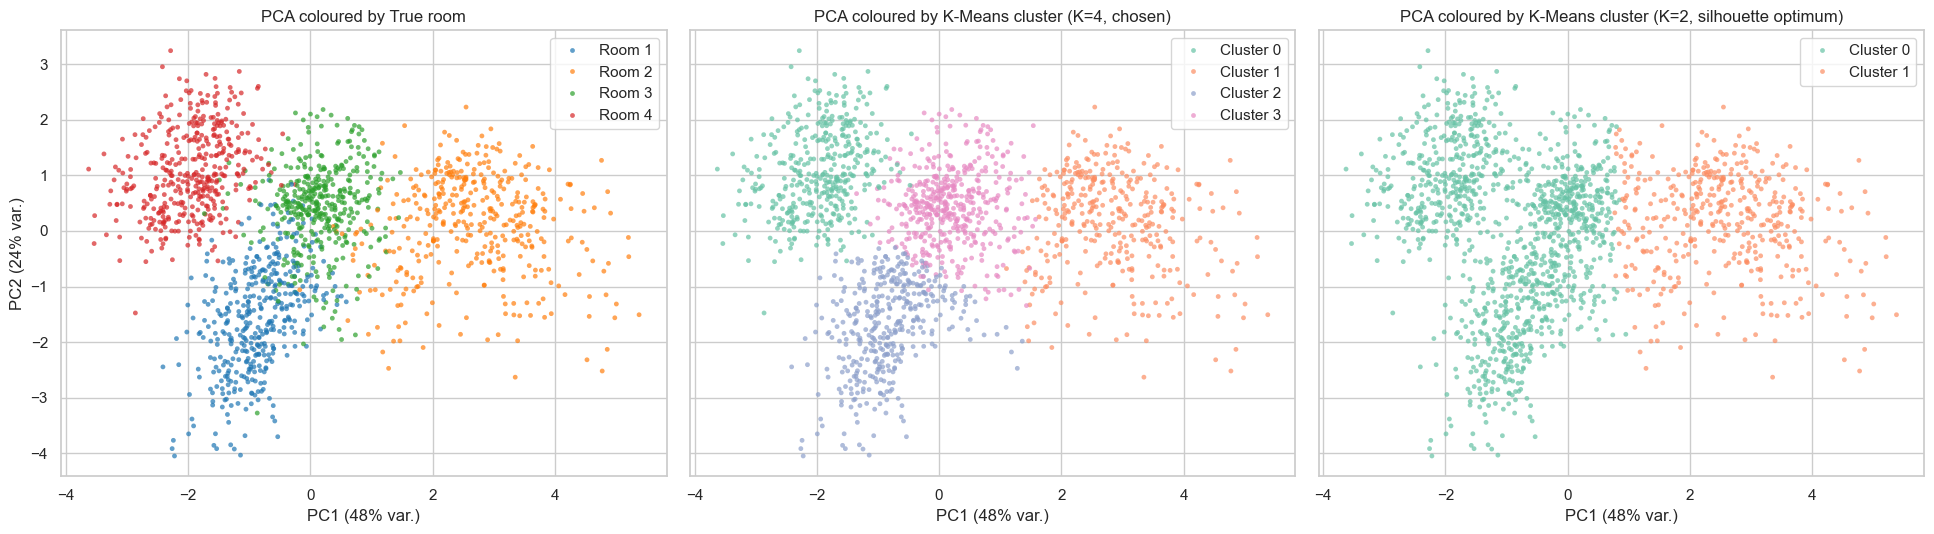

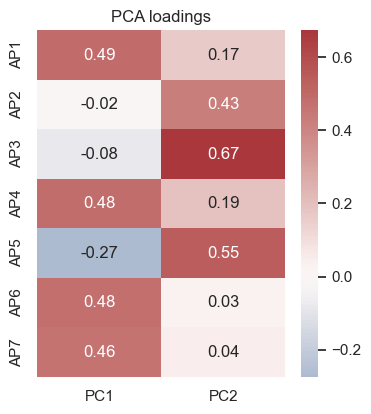

In [11]:
ev = np.array([Pipeline([("scaler", StandardScaler()), ("pca", PCA(random_state=RANDOM_STATE))])
               .fit(X_train.iloc[tr]).named_steps["pca"].explained_variance_ratio_
               for tr, _ in CV.split(X_train, y_train)])
ev_tab = pd.DataFrame({"explained variance": [pm(ev[:, i]) for i in range(7)],
                       "cumulative": [pm(ev[:, :i + 1].sum(1)) for i in range(7)]},
                      index=[f"PC{i+1}" for i in range(7)])
display(ev_tab)

pca_pipe = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=2, random_state=RANDOM_STATE))]).fit(X_train)
Z = pca_pipe.transform(X_train)
pca = pca_pipe.named_steps["pca"]

panels = [("True room", y_train.map(lambda r: f"Room {r}").values, ROOM_NAMES, PALETTE),
          (f"K-Means cluster (K={K_CHOSEN}, chosen)", np.array([f"Cluster {c}" for c in clusters_chosen]), None, "Set2")]
if K_SIL != K_CHOSEN:
    panels.append((f"K-Means cluster (K={K_SIL}, silhouette optimum)", np.array([f"Cluster {c}" for c in clusters_sil]), None, "Set2"))

fig, axes = plt.subplots(1, len(panels), figsize=(6.5 * len(panels), 5.5), sharex=True, sharey=True)
for ax, (title, lab, order, pal) in zip(axes, panels):
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=lab, hue_order=order or sorted(set(lab)),
                    palette=pal, s=12, alpha=0.7, linewidth=0, ax=ax)
    ax.set_title(f"PCA coloured by {title}")
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} var.)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} var.)")
plt.tight_layout(); savefig("pca_room_vs_cluster"); plt.show()

loadings = pd.DataFrame(pca.components_.T, index=AP_COLS, columns=["PC1", "PC2"])
plt.figure(figsize=(4, 4.5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("PCA loadings"); savefig("pca_loadings"); plt.show()